# Lab 00: persiapan Colab dan eksplorasi data

**Tujuan:** membaca beberapa format data Indonesia, memahami arti kolom dan sumbernya,
memeriksa kualitas tabel, lalu menjawab pertanyaan dengan ringkasan dan grafik.
Regresi mulai pada Sesi 01. Untuk demonstrasi singkat, utamakan CSV, Excel, dan SPSS;
contoh format lain tersedia untuk memperluas praktik.

<!-- alur_belajar -->

**Kaitan dengan materi lain**

| Bekal sebelumnya | Fokus notebook ini | Hasil yang dibawa berikutnya |
|---|---|---|
| Belum perlu pengalaman coding; kenali sel, baris, kolom, dan satuan. | Baca tujuh format dari kasus Indonesia yang berbeda; periksa kualitas, ringkasan, dan grafik. | Pertanyaan ekonomi dan tabel yang dipahami untuk regresi dasar Sesi 01. |

**Posisi dalam alur workshop.** Sebelum membangun model, kita perlu mengenali data,
satuan, periode, dan kualitasnya. Hasil eksplorasi membantu merumuskan pertanyaan
yang akan dibahas dengan regresi pada Sesi 01.

## 1. Siapkan Colab dan pembaca data

Jalankan sel berurutan dengan **Shift + Enter**. Paket tambahan membuka Excel,
SPSS/Stata, dan Parquet. Sel instalasi cukup dijalankan satu kali pada runtime.
`URL_DATA` dan `URL_FORMAT` menyimpan alamat data; semua berkas diambil dari GitHub.

<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `set_theme, rcParams, dan label grafik` | Membuat grafik terbaca konsisten. | Tema, ukuran huruf, DPI, judul, xlabel/ylabel, legend, dan tight_layout. | Mengubah tampilan, bukan nilai model; plt.show() menampilkan grafik di notebook. |

In [1]:
%pip install -q "openpyxl==3.1.5" "pyreadstat==1.3.2" "pyarrow==19.0.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"
URL_FORMAT = URL_DATA + "contoh_format/"

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.titleweight": "bold"})
print("pandas siap. Jalankan sel pembacaan data berikutnya.")

pandas siap. Jalankan sel pembacaan data berikutnya.


## 2. Kenali tujuh format dan tujuh kasus Indonesia

Setiap berkas mempunyai isi dan bentuk tabel berbeda. Pembaca pandas mengubahnya
menjadi **DataFrame**, yaitu tabel dengan baris dan kolom. Baca sumber serta arti
variabel sebelum memeriksa hasilnya.

| Format | Kasus dan pertanyaan awal | Unit pengamatan | Sumber |
|---|---|---|---|
| CSV | Makro Indonesia: bagaimana inflasi berubah? | Satu tahun | World Bank |
| Excel | Padi Jawa Barat: daerah mana menghasilkan padi terbanyak? | Satu kabupaten/kota pada 2025 | BPS Jawa Barat |
| SPSS/SAV | Kemiskinan: bagaimana persentasenya berkembang? | Satu tahun Indonesia | World Bank, SI.POV.NAHC |
| Stata/DTA | Internet: bagaimana penggunaannya meluas? | Satu tahun Indonesia | World Bank, IT.NET.USER.ZS |
| TSV | Ekspor: bagaimana nilai nominalnya berubah? | Satu tahun Indonesia | World Bank, NE.EXP.GNFS.CD |
| JSON | Cuaca Jambi: apa prakiraan untuk beberapa waktu berikutnya? | Satu waktu prakiraan tiga jam | BMKG |
| Parquet | Penduduk: bagaimana jumlah penduduk berkembang? | Satu tahun Indonesia | World Bank, SP.POP.TOTL |

Excel merupakan salinan tabel BPS; SAV, DTA, TSV, dan Parquet merupakan konversi
seri publik; JSON BMKG diratakan agar mudah dibaca. Penjelasan dan tautan sumber
tersedia pada setiap kasus. Salinan disimpan agar contoh kelas dapat diulang.

### 2.1 CSV: makroekonomi Indonesia

CSV menyimpan satu baris data pada setiap baris teks, dengan pemisah antarkolom.
Kita memakai tabel ini lagi pada pemeriksaan kualitas dan grafik di bagian berikutnya.

<!-- kamus_variabel:makro_indonesia_tahunan.csv -->

### Kenali data: Makroekonomi Indonesia tahunan

**Data:** `data/makro_indonesia_tahunan.csv`. **Satu baris:** satu tahun kalender untuk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `negara` | Kode negara; IDN menunjukkan Indonesia. | Kode ISO negara |
| `tahun` | Tahun kalender pengamatan. | Tahun |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN |

Kurs_USD untuk Indonesia bersatuan rupiah per US$1. Inflasi dan pertumbuhan adalah laju persen, bukan nilai level harga atau level PDB.

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.read_csv` | Membaca CSV atau TSV menjadi tabel. | Alamat berkas; sep="\t" memilih pemisah tab pada TSV. | DataFrame; periksa nama kolom dan ukuran sebelum analisis. |
| `pd.read_excel` | Membaca lembar Excel yang dipilih. | Alamat .xlsx; sheet_name="data" memilih lembar data. | DataFrame dari satu lembar, bukan seluruh buku Excel. |
| `urlretrieve` | Mengunduh SPSS ke runtime Colab. | Alamat sumber, lalu nama berkas lokal tujuan. | Berkas .sav lokal yang dapat dibuka pembaca SPSS. |
| `pd.read_spss` | Membuka tabel SPSS. | Nama .sav lokal; convert_categoricals=False mempertahankan kode angka. | DataFrame; nama dan arti kolom tetap perlu dibaca pada kamus data. |
| `pd.read_stata` | Membuka tabel Stata. | Alamat .dta; convert_categoricals=False mempertahankan kode angka. | DataFrame; tahun dan satuan diperiksa kembali. |
| `pd.read_json` | Membaca rekaman JSON yang sudah diratakan. | Alamat .json; orient="records" berarti satu objek mewakili satu baris. | Tabel prakiraan cuaca, bukan pengamatan cuaca yang sudah terjadi. |
| `pd.read_parquet` | Membuka tabel Parquet bertipe kolom. | Alamat .parquet; mesin pyarrow dipasang pada sel persiapan. | DataFrame dengan tipe angka tersimpan di dalam berkas. |
| `head` | Melihat contoh isi tabel. | Tanpa angka menampilkan lima baris; head(10) menampilkan sepuluh. | Cuplikan awal, bukan ringkasan seluruh data. |
| `shape` | Memeriksa ukuran tabel. | Atribut tanpa tanda kurung; shape[0] untuk baris, shape[1] untuk kolom. | Pasangan (jumlah baris, jumlah kolom). |
| `astype` | Mengubah tipe kolom atau tanda kondisi menjadi angka. | int untuk bilangan bulat, float untuk desimal; True menjadi 1 dan False menjadi 0. | Kolom bertipe baru; periksa arti kode sebelum membuat dummy. |
| `sort_values dan nlargest` | Mengurutkan tabel atau memilih nilai terbesar. | Nama kolom; ascending=False berarti menurun; nlargest(5, kolom) memilih lima terbesar. | Peringkat menurut variabel tersebut, bukan peringkat kesejahteraan secara umum. |
| `barh dan bar` | Membandingkan nilai antarkelompok. | Nama kelompok dan nilainya; barh memberi batang horizontal. | Panjang batang menunjukkan nilai; periksa satuan dan apakah sumbu dimulai dari nol. |

In [3]:
makro_csv = pd.read_csv(URL_DATA + "makro_indonesia_tahunan.csv")
print("Baris dan kolom:", makro_csv.shape)
makro_csv.head()

Baris dan kolom: (26, 7)


,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### 2.2 Excel: produksi padi dan beras di Jawa Barat

`sheet_name="data"` memilih lembar data; lembar `sumber` menyimpan asal dan definisinya.
Produksi padi dan produksi beras mempunyai satuan ton, tetapi mengukur hasil berbeda.

<!-- kamus_variabel:produksi_padi_jawa_barat.xlsx -->

### Kenali data: Produksi padi dan beras di Jawa Barat, 2025

**Data:** `data/contoh_format/produksi_padi_jawa_barat.xlsx`. **Satu baris:** satu kabupaten atau kota di Jawa Barat pada 2025.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `kabupaten_kota` | Nama kabupaten atau kota di Provinsi Jawa Barat. | Nama wilayah |
| `tahun` | Tahun produksi yang dilaporkan. | Tahun kalender |
| `produksi_padi_ton` | Jumlah padi dalam kualitas gabah kering giling yang diproduksi selama setahun. | Ton per tahun |
| `produksi_beras_ton` | Jumlah produksi beras menurut tabel BPS; berbeda dari berat gabah. | Ton per tahun |

Salinan Excel dibuat untuk latihan dari tabel statistik BPS Jawa Barat, tahun data 2025, diperbarui 12 Februari 2026. Produksi padi memakai gabah kering giling. Baris total provinsi tidak dimasukkan agar tidak dihitung dua kali. Ini bukan berkas Excel unduhan asli BPS.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada data awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `produksi_juta_ton` | Produksi padi dibagi satu juta untuk memperjelas sumbu grafik. | Juta ton gabah kering giling per tahun |

Sumber definisi: [rujukan data](https://jabar.bps.go.id/id/statistics-table/3/ZDNaak0yODBUVTlGYW5sa2REUkVUVVY1YVZkbmR6MDkjMw%3D%3D/produksi-padi-sup-1--sup--dan-beras-menurut-kabupaten-kota-di-provinsi-jawa-barat--2020.html).

[Tabel atau API asal](https://jabar.bps.go.id/id/statistics-table/3/ZDNaak0yODBUVTlGYW5sa2REUkVUVVY1YVZkbmR6MDkjMw%3D%3D/produksi-padi-sup-1--sup--dan-beras-menurut-kabupaten-kota-di-provinsi-jawa-barat--2020.html). Salinan diakses pada 2026-10-25; berkas latihan disimpan agar hasil kelas dapat diulang.


In [4]:
padi_excel = pd.read_excel(URL_FORMAT + "produksi_padi_jawa_barat.xlsx", sheet_name="data")
print("Baris dan kolom:", padi_excel.shape)
padi_excel.head()

Baris dan kolom: (27, 4)


,kabupaten_kota,tahun,produksi_padi_ton,produksi_beras_ton
0,Bogor,2025,345984,199800
1,Sukabumi,2025,660107,381200
2,Cianjur,2025,800735,462410
3,Bandung,2025,353307,204028
4,Garut,2025,555727,320922


### 2.3 SPSS: kemiskinan Indonesia

`read_spss` membuka format SAV. `urlretrieve` mengunduhnya ke runtime karena pembaca
SPSS memerlukan berkas lokal. Tidak ada pemilihan folder atau pemeriksaan file.
`astype(int)` menampilkan tahun sebagai bilangan bulat.

<!-- kamus_variabel:kemiskinan_indonesia.sav -->

### Kenali data: Kemiskinan Indonesia menurut garis kemiskinan nasional

**Data:** `data/contoh_format/kemiskinan_indonesia.sav`. **Satu baris:** satu tahun pengamatan Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `tahun` | Tahun pengamatan Indonesia. | Tahun kalender |
| `kemiskinan_persen` | Persentase penduduk di bawah garis kemiskinan nasional menurut seri World Bank. | Persen penduduk; 10 berarti 10% |

SPSS/SAV ini dikonversi dari seri publik World Bank SI.POV.NAHC, mulai tahun 2000. Ini data agregat tahunan, bukan mikrodata rumah tangga BPS. Tahun tanpa nilai tidak diisi dengan nol.

Sumber definisi: [rujukan data](https://data.worldbank.org/indicator/SI.POV.NAHC?locations=ID).

[Tabel atau API asal](https://api.worldbank.org/v2/country/IDN/indicator/SI.POV.NAHC?format=json&per_page=1000). Salinan diakses pada 2026-10-25; berkas latihan disimpan agar hasil kelas dapat diulang.


In [5]:
from urllib.request import urlretrieve

urlretrieve(URL_FORMAT + "kemiskinan_indonesia.sav", "kemiskinan_indonesia.sav")
kemiskinan_spss = pd.read_spss("kemiskinan_indonesia.sav")
kemiskinan_spss["tahun"] = kemiskinan_spss["tahun"].astype(int)
print("Baris dan kolom:", kemiskinan_spss.shape)
kemiskinan_spss.head()

Baris dan kolom: (26, 2)


,tahun,kemiskinan_persen
0,2000,19.1
1,2001,18.4
2,2002,18.2
3,2003,17.4
4,2004,16.7


### 2.4 Stata: pengguna internet di Indonesia

`read_stata` membuka format DTA. Perhatikan bahwa nama kolom, jumlah baris, periode,
dan satuannya berbeda dari tabel kemiskinan. Persentase pengguna bukan jumlah pengguna.

<!-- kamus_variabel:pengguna_internet_indonesia.dta -->

### Kenali data: Penggunaan internet di Indonesia

**Data:** `data/contoh_format/pengguna_internet_indonesia.dta`. **Satu baris:** satu tahun pengamatan Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `tahun` | Tahun pengamatan Indonesia. | Tahun kalender |
| `pengguna_internet_persen` | Bagian penduduk yang menggunakan internet menurut seri World Bank. | Persen penduduk; 25 berarti 25% |

Stata/DTA ini dikonversi dari seri World Bank IT.NET.USER.ZS. Tahun tersedia dipertahankan mulai 1990; tahun tanpa nilai dikeluarkan, bukan dianggap nol.

Sumber definisi: [rujukan data](https://data.worldbank.org/indicator/IT.NET.USER.ZS?locations=ID).

[Tabel atau API asal](https://api.worldbank.org/v2/country/IDN/indicator/IT.NET.USER.ZS?format=json&per_page=1000). Salinan diakses pada 2026-10-25; berkas latihan disimpan agar hasil kelas dapat diulang.


In [6]:
internet_stata = pd.read_stata(URL_FORMAT + "pengguna_internet_indonesia.dta")
print("Baris dan kolom:", internet_stata.shape)
internet_stata.head()

Baris dan kolom: (32, 2)


,tahun,pengguna_internet_persen
0,1990,0.00000
1,1994,0.00106
2,1995,0.02610
3,1996,0.05660
4,1997,0.19500


### 2.5 TSV: ekspor barang dan jasa Indonesia

TSV memakai tab sebagai pemisah, sehingga `read_csv` diberi `sep="\t"`.
Nilai ekspor memakai dolar AS berlaku. Kenaikan nominalnya dapat mencerminkan
perubahan volume, harga, dan kurs; ketiganya belum dipisahkan pada tabel ini.

<!-- kamus_variabel:ekspor_indonesia.tsv -->

### Kenali data: Ekspor barang dan jasa Indonesia

**Data:** `data/contoh_format/ekspor_indonesia.tsv`. **Satu baris:** satu tahun pengamatan Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `tahun` | Tahun pencatatan ekspor Indonesia. | Tahun kalender |
| `ekspor_usd` | Nilai ekspor barang dan jasa pada harga berlaku. | Dolar AS berlaku, bukan rupiah dan bukan dolar konstan |

TSV ini disiapkan dari seri World Bank NE.EXP.GNFS.CD, mulai 1995. Nilai memakai dolar AS berlaku, sehingga perubahan nominalnya juga dipengaruhi harga dan kurs; jangan langsung membacanya sebagai pertumbuhan volume ekspor.

Sumber definisi: [rujukan data](https://data.worldbank.org/indicator/NE.EXP.GNFS.CD?locations=ID).

[Tabel atau API asal](https://api.worldbank.org/v2/country/IDN/indicator/NE.EXP.GNFS.CD?format=json&per_page=1000). Salinan diakses pada 2026-10-25; berkas latihan disimpan agar hasil kelas dapat diulang.


In [7]:
ekspor_tsv = pd.read_csv(URL_FORMAT + "ekspor_indonesia.tsv", sep="\t")
print("Baris dan kolom:", ekspor_tsv.shape)
ekspor_tsv.head()

Baris dan kolom: (31, 2)


,tahun,ekspor_usd
0,1995,5.318531e+10
1,1996,5.871720e+10
2,1997,6.010604e+10
3,1998,5.055573e+10
4,1999,4.972026e+10


### 2.6 JSON: prakiraan cuaca Kota Jambi

`orient="records"` membaca daftar rekaman dengan nama kolom pada setiap rekaman.
Contoh ini berasal dari prakiraan BMKG untuk Simpang IV Sipin, Telanaipura, Kota Jambi.
Ini salinan yang diambil 25 Oktober 2026; **prakiraan berbeda dari pengamatan cuaca**.
Cuaca berkaitan dengan perencanaan pertanian dan transportasi, tetapi contoh ini hanya untuk membaca data.

<!-- kamus_variabel:prakiraan_cuaca_jambi.json -->

### Kenali data: Prakiraan cuaca Simpang IV Sipin, Kota Jambi

**Data:** `data/contoh_format/prakiraan_cuaca_jambi.json`. **Satu baris:** satu waktu prakiraan cuaca tiga jam di Kelurahan Simpang IV Sipin, Kecamatan Telanaipura, Kota Jambi.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `waktu_lokal` | Tanggal dan jam yang diramalkan, dalam waktu setempat. | YYYY-MM-DD HH:MM:SS, WIB |
| `suhu_c` | Suhu udara yang diprakirakan BMKG pada waktu tersebut. | Derajat Celsius |
| `kelembapan_persen` | Kelembapan udara relatif yang diprakirakan. | Persen |
| `angin_km_jam` | Kecepatan angin yang diprakirakan. | Kilometer per jam |
| `kondisi` | Deskripsi cuaca dari BMKG, misalnya berawan atau hujan ringan. | Kategori teks |
| `kelurahan` | Nama lokasi prakiraan; semua baris pada contoh ini berada di Simpang IV Sipin. | Nama kelurahan |
| `waktu_produksi_utc` | Waktu BMKG memproduksi paket prakiraan, bukan waktu kejadian cuaca. | UTC |

Sumber BMKG (Badan Meteorologi, Klimatologi, dan Geofisika). JSON API bertingkat diratakan menjadi daftar rekaman untuk latihan pd.read_json. Nilai prakiraan tidak diubah. Ini salinan yang diambil 25 Oktober 2026; prakiraan bukan pengamatan cuaca yang sudah terjadi. Waktu lokal memakai WIB, sedangkan waktu produksi memakai UTC.

Sumber definisi: [rujukan data](https://data.bmkg.go.id/prakiraan-cuaca/).

[Tabel atau API asal](https://api.bmkg.go.id/publik/prakiraan-cuaca?adm4=15.71.01.1001). Salinan diakses pada 2026-10-25; berkas latihan disimpan agar hasil kelas dapat diulang.


In [8]:
cuaca_json = pd.read_json(URL_FORMAT + "prakiraan_cuaca_jambi.json", orient="records")
print("Baris dan kolom:", cuaca_json.shape)
cuaca_json.head()

Baris dan kolom: (17, 7)


,waktu_lokal,suhu_c,kelembapan_persen,angin_km_jam,kondisi,kelurahan,waktu_produksi_utc
0,2026-10-25 23:00:00,26,97,4.3,Udara Kabur,Simpang IV Sipin,2026-10-25T12:00:00
1,2026-10-26 02:00:00,25,96,4.9,Hujan Ringan,Simpang IV Sipin,2026-10-25T12:00:00
2,2026-10-26 05:00:00,24,97,4.6,Udara Kabur,Simpang IV Sipin,2026-10-25T12:00:00
3,2026-10-26 08:00:00,25,92,5.2,Udara Kabur,Simpang IV Sipin,2026-10-25T12:00:00
4,2026-10-26 11:00:00,29,80,5.5,Udara Kabur,Simpang IV Sipin,2026-10-25T12:00:00


### 2.7 Parquet: jumlah penduduk Indonesia

Parquet menyimpan data per kolom dan mempertahankan tipe data. `read_parquet`
membukanya langsung menjadi DataFrame. Perhatikan satuan **orang**, bukan juta orang.

<!-- kamus_variabel:penduduk_indonesia.parquet -->

### Kenali data: Jumlah penduduk Indonesia

**Data:** `data/contoh_format/penduduk_indonesia.parquet`. **Satu baris:** satu tahun estimasi jumlah penduduk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `tahun` | Tahun estimasi penduduk. | Tahun kalender |
| `jumlah_penduduk` | Total estimasi penduduk Indonesia pada tahun tersebut menurut seri World Bank. | Orang |

Parquet ini dikonversi dari seri World Bank SP.POP.TOTL mulai 1960. Jumlah penduduk adalah estimasi menurut seri sumber; satuannya orang, bukan ribu atau juta orang.

Sumber definisi: [rujukan data](https://data.worldbank.org/indicator/SP.POP.TOTL?locations=ID).

[Tabel atau API asal](https://api.worldbank.org/v2/country/IDN/indicator/SP.POP.TOTL?format=json&per_page=1000). Salinan diakses pada 2026-10-25; berkas latihan disimpan agar hasil kelas dapat diulang.


In [9]:
penduduk_parquet = pd.read_parquet(URL_FORMAT + "penduduk_indonesia.parquet")
print("Baris dan kolom:", penduduk_parquet.shape)
penduduk_parquet.head()

Baris dan kolom:

 (66, 2)


,tahun,jumlah_penduduk
0,1960,88296070
1,1961,90791249
2,1962,93375850
3,1963,96051424
4,1964,98833749


### 2.8 Pilih grafik sesuai pertanyaan

Gunakan tabel Excel untuk membandingkan wilayah. `nlargest` memilih lima produksi
padi terbesar; `sort_values` menata urutannya sebelum digambar sebagai batang mendatar.

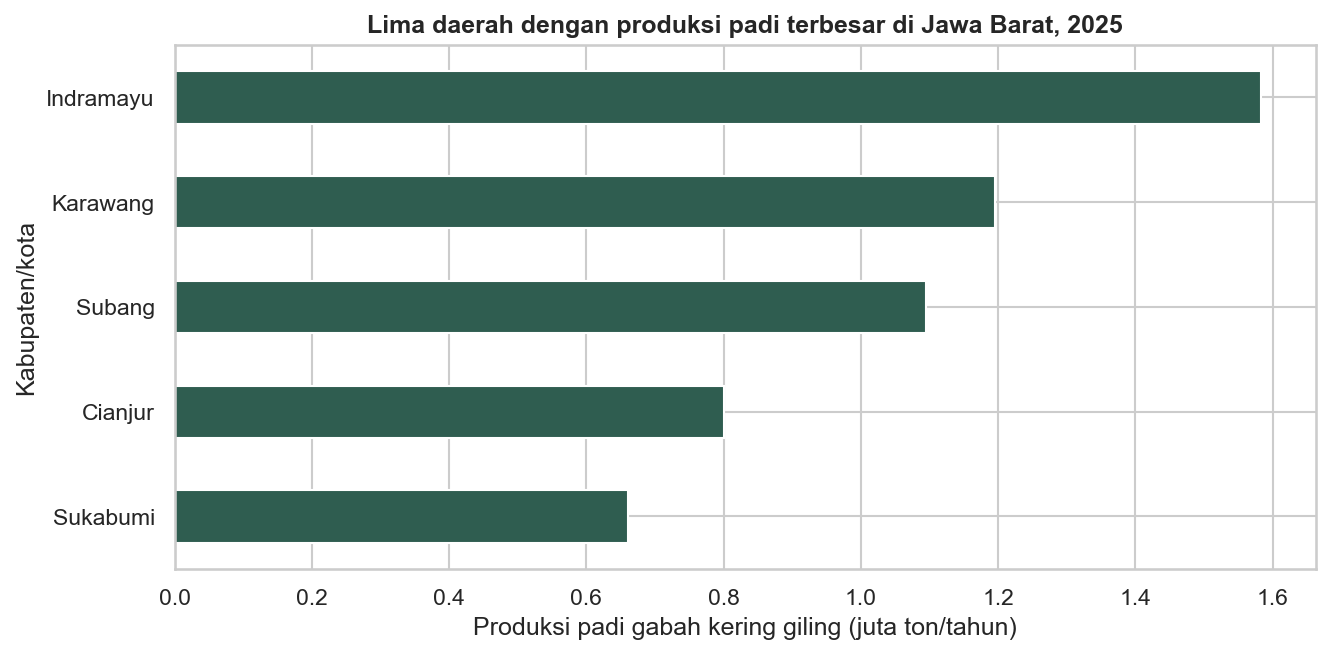

In [10]:
padi_terbesar = padi_excel.nlargest(5, "produksi_padi_ton")
padi_terbesar = padi_terbesar.sort_values("produksi_padi_ton")
padi_terbesar["produksi_juta_ton"] = padi_terbesar["produksi_padi_ton"] / 1000000
ax = padi_terbesar.plot.barh(
    x="kabupaten_kota", y="produksi_juta_ton",
    figsize=(9, 4.5), legend=False, color="#2F5D50"
)
ax.set_xlabel("Produksi padi gabah kering giling (juta ton/tahun)")
ax.set_ylabel("Kabupaten/kota")
ax.set_title("Lima daerah dengan produksi padi terbesar di Jawa Barat, 2025")
plt.tight_layout()
plt.show()

**Cara membaca:** batang lebih panjang menunjukkan jumlah produksi lebih besar
pada 2025. Sumbu memakai juta ton: 1,5 berarti 1.500.000 ton. Kolom
`produksi_juta_ton` diperoleh dengan membagi ton dengan 1.000.000. Produksi total belum mengukur produktivitas per hektar, karena luas
panen belum menjadi pembagi. Perbedaan konsep ini membantu saat Sesi 01 membahas
produktivitas padi dan faktor-faktor yang berkaitan dengannya.

Setiap berkas tadi memiliki kasus sendiri. Untuk latihan kualitas data berikutnya,
kita kembali ke **CSV makro Indonesia** agar pemeriksaan dari satu langkah ke langkah berikutnya konsisten.

## 3. Periksa isi dan kualitas tabel

`shape` menampilkan jumlah baris dan kolom. `info()` menampilkan nama kolom,
tipe data, dan banyaknya nilai yang terisi. `negara` adalah teks, sedangkan
tahun dan indikator ekonomi pada contoh ini berupa angka.

<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `info` | Memeriksa tipe data dan jumlah nilai terisi. | Tabel yang sedang dipelajari. | Tampilan tipe tiap kolom; angka yang terbaca sebagai teks perlu diperiksa. |
| `isna dan sum` | Menghitung nilai kosong per kolom. | isna() menandai nilai kosong; sum() menghitung tanda True. | Jumlah kosong; nilai nol dan teks kosong belum tentu dikenali sebagai NA. |
| `duplicated` | Memeriksa baris yang isinya berulang. | Tanpa subset, seluruh kolom dibandingkan; sum() menghitung duplikasi. | Pengulangan belum tentu salah; cocokkan dengan unit pengamatan. |

In [11]:
print("Jumlah baris dan kolom:", makro_csv.shape)
makro_csv.info()

Jumlah baris dan kolom: (26, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   negara          26 non-null     object 
 1   tahun           26 non-null     int64  
 2   PDB_Growth      26 non-null     float64
 3   Inflasi         26 non-null     float64
 4   Pengangguran    26 non-null     float64
 5   Kurs_USD        26 non-null     float64
 6   Angkatan_Kerja  26 non-null     int64  
dtypes: float64(4), int64(2), object(1)
memory usage: 1.6+ KB


### Cari nilai kosong dan baris berulang

`isna()` memeriksa nilai kosong. `sum()` menghitungnya pada setiap kolom.
`duplicated()` memeriksa baris yang seluruh isinya sama dengan baris sebelumnya.
Nilai kosong berbeda dari angka nol; jangan langsung mengisinya dengan nol.

In [12]:
print("Nilai kosong per kolom:")
print(makro_csv.isna().sum())
print("Baris berulang:", makro_csv.duplicated().sum())

Nilai kosong per kolom:
negara            0
tahun             0
PDB_Growth        0
Inflasi           0
Pengangguran      0
Kurs_USD          0
Angkatan_Kerja    0
dtype: int64
Baris berulang: 0


Salinan ini tidak mempunyai nilai kosong atau baris berulang. Pemeriksaan
tetap dilakukan setiap kali menerima data lain. Kolom `negara` bernilai `IDN`
pada semua baris karena contoh ini hanya memuat Indonesia.

## 4. Ringkas angka dan pilih pengamatan

`describe()` merangkum jumlah nilai, rata-rata, simpangan baku, minimum,
kuartil, dan maksimum. Baca satu kolom dahulu, misalnya `Inflasi`.
`50%` adalah median: nilai tengah setelah data diurutkan.

<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `describe` | Meringkas sebaran kolom angka. | Kolom yang dipilih; round(2) membulatkan tampilan. | count, mean, std, min, kuartil, dan max; 50% adalah median. |
| `mean dan median` | Meringkas pusat data. | mean() rata-rata; median() nilai tengah; kolom dan satuan dipilih terlebih dahulu. | Satu nilai per kolom/kelompok; rata-rata tahunan bukan perubahan kumulatif. |

In [13]:
kolom_angka = ["PDB_Growth", "Inflasi", "Pengangguran"]
makro_csv[kolom_angka].describe().round(2)

,PDB_Growth,Inflasi,Pengangguran
count,26.00,26.00,26.00
mean,4.90,5.67,5.20
std,1.57,3.27,1.58
min,-2.07,1.56,3.24
25%,4.89,3.56,3.88
50%,5.04,4.76,4.49
75%,5.54,6.41,6.48
max,6.35,13.11,8.06


Rata-rata menjumlahkan nilai lalu membaginya dengan jumlah tahun.
Median mengambil nilai tengah, sehingga pengaruh nilai sangat tinggi lebih
kecil. Ringkasan berikut adalah rata-rata sederhana antar tahun, bukan
akumulasi inflasi atau pertumbuhan ekonomi selama seluruh periode.

In [14]:
print("Rata-rata inflasi:", round(makro_csv["Inflasi"].mean(), 2), "%")
print("Median inflasi:", round(makro_csv["Inflasi"].median(), 2), "%")

Rata-rata inflasi: 5.67 %
Median inflasi: 4.76 %


### Pilih tahun 2015 dan sesudahnya

`>=` berarti lebih besar atau sama dengan. Bagian di dalam kurung siku
memilih baris yang memenuhi kondisi; perintah berikutnya memilih kolom.

In [15]:
periode_baru = makro_csv[makro_csv["tahun"] >= 2015]
periode_baru[["tahun", "PDB_Growth", "Inflasi", "Pengangguran"]]

,tahun,PDB_Growth,Inflasi,Pengangguran
15,2015,4.876322,6.363121,4.514
16,2016,5.033069,3.525805,4.301
17,2017,5.069786,3.808799,3.783
18,2018,5.174292,3.198348,4.387
19,2019,5.019288,3.030585,3.590
20,2020,-2.065512,1.919835,4.255
21,2021,3.702886,1.560079,3.827
22,2022,5.307197,4.209465,3.462
23,2023,5.048831,3.669387,3.308
24,2024,5.032575,2.181513,3.301


## 5. Gambarkan data untuk menjawab pertanyaan

Gunakan grafik garis untuk membaca perubahan waktu dan histogram untuk membaca sebaran nilai.

### Grafik garis: apa yang berubah sepanjang waktu?

Sumbu mendatar memakai tahun, sedangkan sumbu tegak memakai inflasi tahunan.
Gunakan CSV makro Indonesia agar satuan dan pengamatan tetap sama dengan ringkasan sebelumnya.

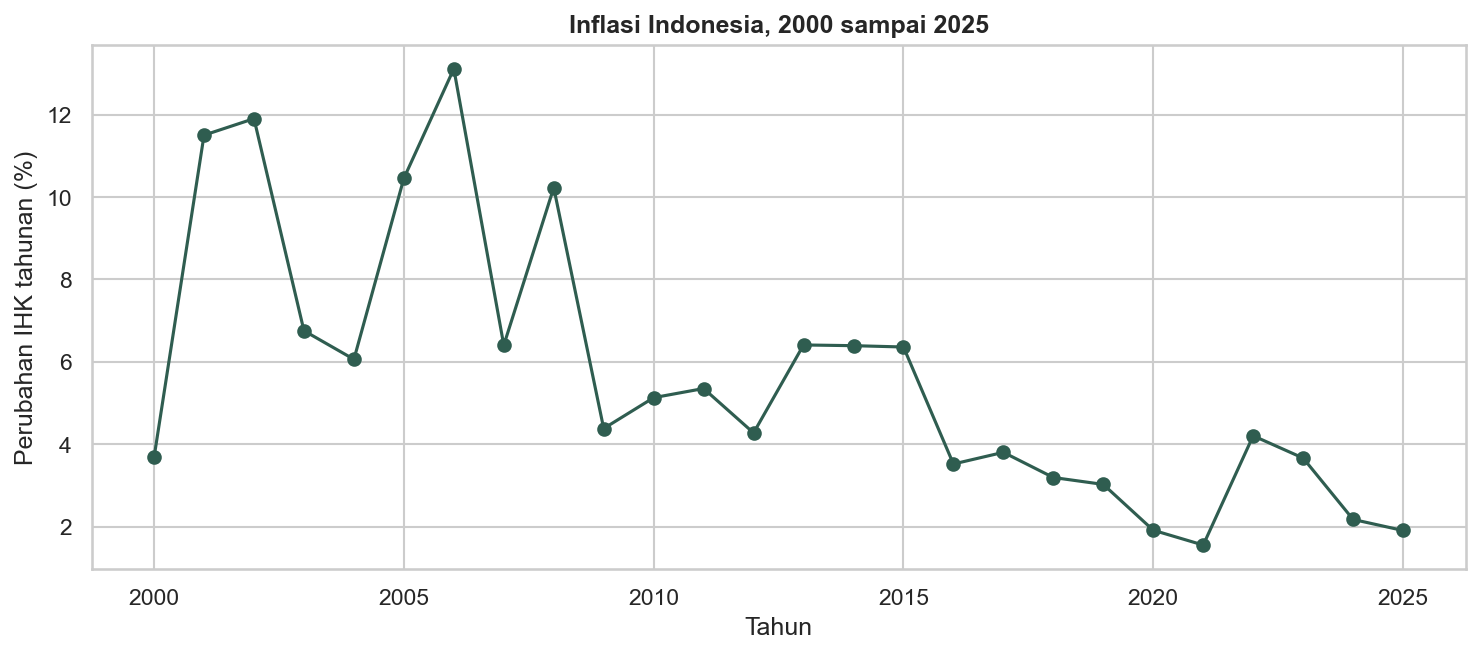

In [16]:
makro_csv.plot(x="tahun", y="Inflasi", marker="o", color="#2F5D50",
                figsize=(10, 4.5), legend=False)
plt.title("Inflasi Indonesia, 2000 sampai 2025")
plt.xlabel("Tahun")
plt.ylabel("Perubahan IHK tahunan (%)")
plt.xticks([2000, 2005, 2010, 2015, 2020, 2025])
plt.tight_layout()
plt.show()

**Cara membaca:** satu titik adalah satu tahun. Nilai yang lebih tinggi
menunjukkan laju kenaikan Indeks Harga Konsumen (IHK) yang lebih besar.
Nilai 5 berarti kenaikan sekitar 5 persen dari tahun sebelumnya. Grafik
memperlihatkan perubahan laju inflasi, bukan level harga. Inflasi tahunan
World Bank ini jangan disamakan langsung dengan inflasi bulanan.

### Histogram: seberapa sering suatu rentang nilai muncul?

Grafik garis menjaga urutan tahun. Histogram mengelompokkan nilai inflasi
ke dalam enam rentang, lalu menghitung banyaknya tahun pada setiap rentang.

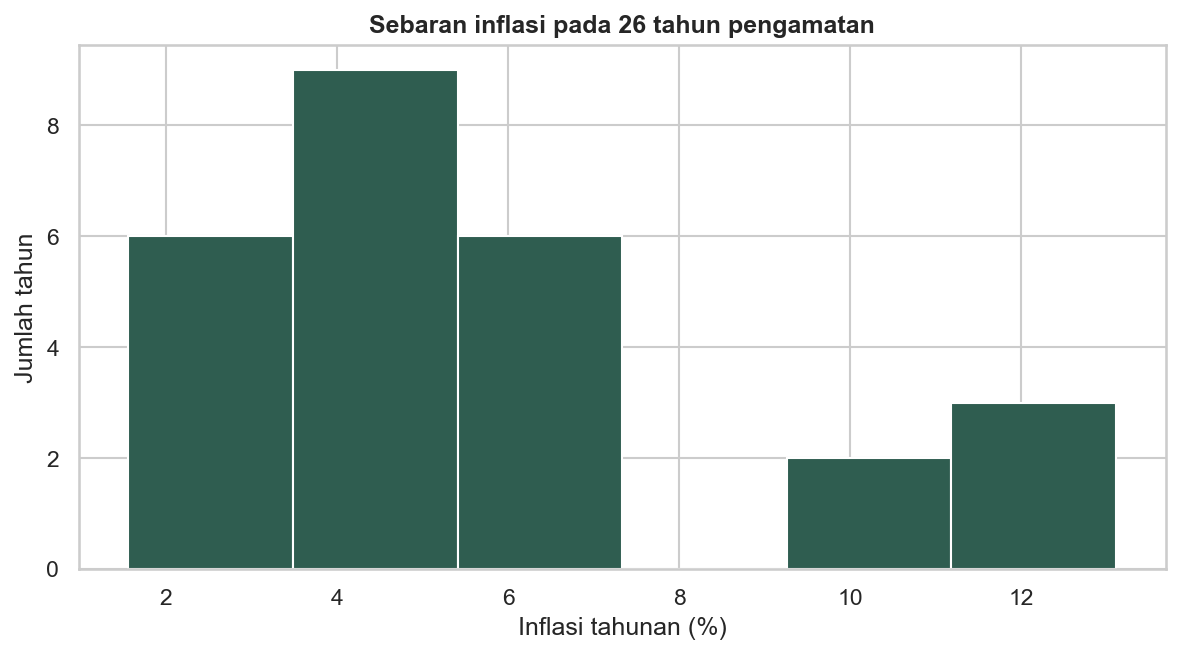

In [17]:
plt.figure(figsize=(8, 4.5))
plt.hist(makro_csv["Inflasi"], bins=6, color="#2F5D50", edgecolor="white")
plt.xlabel("Inflasi tahunan (%)")
plt.ylabel("Jumlah tahun")
plt.title("Sebaran inflasi pada 26 tahun pengamatan")
plt.tight_layout()
plt.show()

**Cara membaca:** tinggi batang menunjukkan jumlah tahun pada rentang
inflasi di bawahnya. Jumlah seluruh batang adalah 26 tahun. Batang yang lebih
tinggi berarti rentang itu lebih sering muncul. Urutan tahun tidak terlihat
pada histogram; gunakan grafik garis untuk melihat kapan nilainya terjadi.

## 6. Bandingkan data 34 provinsi pada 2021

Tabel makro membandingkan tahun. Tabel berikut membandingkan provinsi pada
tahun yang sama. Kenali arti kolom sebelum memilih indikator yang digambar.
Kita memakai `Provinsi`, `Kemiskinan`, dan `IPM` untuk eksplorasi awal.

<!-- kamus_variabel:indikator_provinsi_2021.csv -->

### Kenali data: Indikator 34 provinsi tahun 2021

**Data:** `data/indikator_provinsi_2021.csv`. **Satu baris:** satu provinsi pada tahun 2021 dalam kompilasi sumber.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `Provinsi` | Nama provinsi yang diamati. | Nama wilayah |
| `PDRB_Kapita` | Produk Domestik Regional Bruto per penduduk, ukuran output ekonomi per kapita. | Skala sumber; dipakai sebagai ribu rupiah dalam tutorial |
| `IPM` | Indeks Pembangunan Manusia yang merangkum dimensi kesehatan, pendidikan, dan taraf hidup. | Poin indeks, bukan persen |
| `Pengangguran` | Tingkat Pengangguran Terbuka (TPT). | Persen angkatan kerja |
| `Kemiskinan` | Penduduk yang berada di bawah garis kemiskinan. | Persen penduduk |
| `AHH_Laki` | Angka Harapan Hidup laki-laki pada kompilasi sumber. | Tahun |
| `AHH_Perempuan` | Angka Harapan Hidup perempuan pada kompilasi sumber. | Tahun |
| `APS_7_12` | Angka Partisipasi Sekolah penduduk umur 7 sampai 12 tahun. | Persen penduduk kelompok umur tersebut |
| `APS_13_15` | Angka Partisipasi Sekolah penduduk umur 13 sampai 15 tahun. | Persen penduduk kelompok umur tersebut |
| `APS_16_18` | Angka Partisipasi Sekolah penduduk umur 16 sampai 18 tahun. | Persen penduduk kelompok umur tersebut |
| `APS_19_23` | Angka Partisipasi Sekolah penduduk umur 19 sampai 23 tahun. | Persen penduduk kelompok umur tersebut |
| `Perokok` | Persentase perokok pada kompilasi data provinsi. | Persen; cakupan umur mengikuti sumber |

Berkas ini adalah kompilasi indikator, bukan tabel metadata lengkap BPS. Cakupan indikator dan skala PDRB perlu diperiksa pada sumber BPS sebelum dipakai untuk riset; barisnya mengikuti 34 provinsi pada tahun 2021.

Sumber definisi: [rujukan data](https://github.com/sainsdataid/dataset/blob/main/Data%2034%20Provinsi%202021.csv).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `subplots, scatter, dan plot` | Membuat ruang grafik lalu menampilkan hubungan atau pola waktu. | figsize ukuran; scatter untuk titik, plot untuk garis; sumbu dan satuan diberi label. | Titik menunjukkan pengamatan; garis mengikuti urutan X sehingga data perlu diurutkan bila perlu. |

In [18]:
provinsi = pd.read_csv(URL_DATA + "indikator_provinsi_2021.csv")
provinsi[["Provinsi", "Kemiskinan", "IPM"]].head()

,Provinsi,Kemiskinan,IPM
0,Aceh,15.33,72.18
1,Sumatera Utara,9.01,72.00
2,Sumatera Barat,6.63,72.65
3,Riau,7.12,72.94
4,Jambi,8.09,71.63


### Grafik batang: bandingkan wilayah

`nlargest` memilih provinsi dengan persentase kemiskinan tertinggi.
`sort_values` mengatur urutan agar batang paling tinggi berada di bagian atas.
Tanda `%` menunjukkan persentase penduduk, bukan jumlah orang.

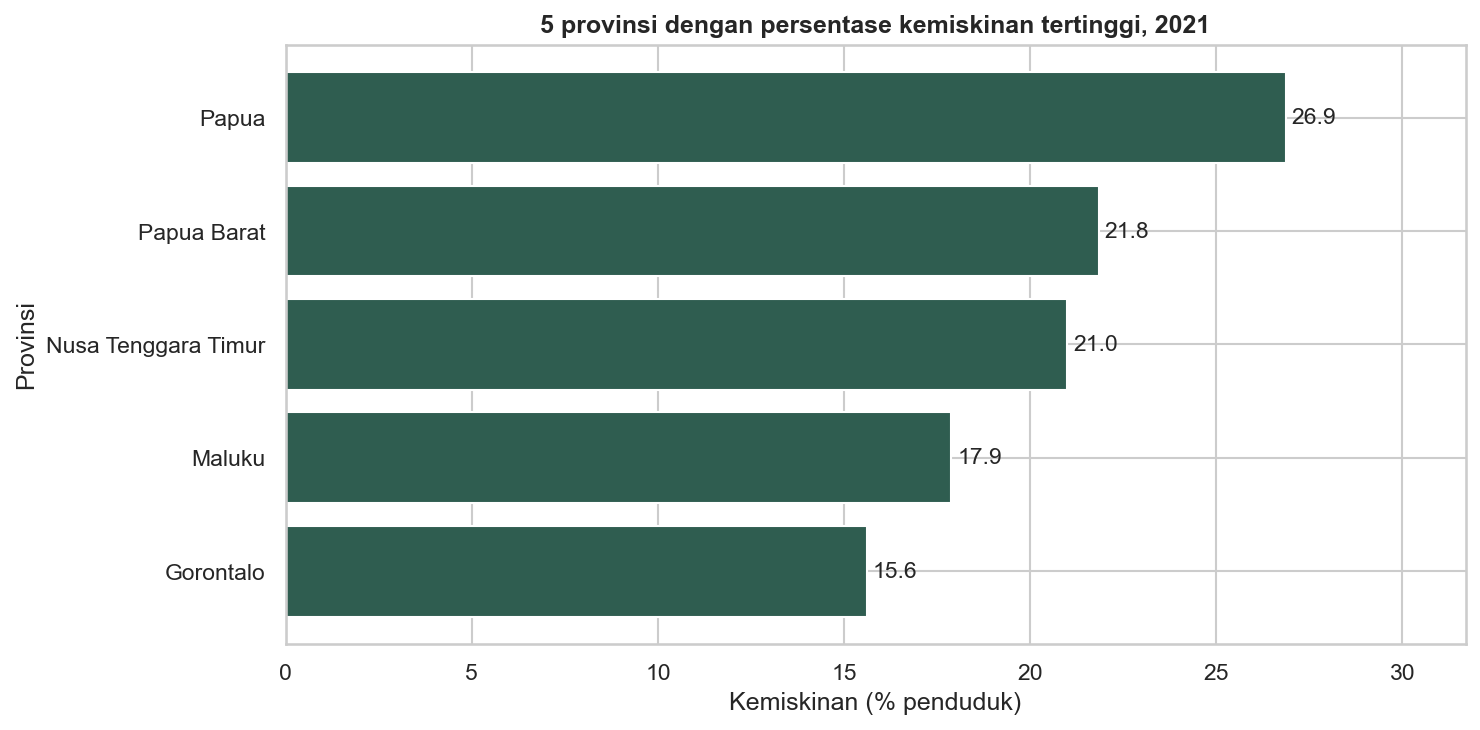

In [19]:
peringkat = provinsi.nlargest(5, "Kemiskinan")
peringkat = peringkat.sort_values("Kemiskinan")
fig, ax = plt.subplots(figsize=(10, 5))
batang = ax.barh(peringkat["Provinsi"], peringkat["Kemiskinan"], color="#2F5D50")
ax.bar_label(batang, fmt="%.1f", padding=3)
ax.set_xlabel("Kemiskinan (% penduduk)")
ax.set_ylabel("Provinsi")
ax.set_title("5 provinsi dengan persentase kemiskinan tertinggi, 2021")
ax.set_xlim(0, peringkat["Kemiskinan"].max() * 1.18)
plt.tight_layout()
plt.show()

**Cara membaca:** satu batang mewakili satu provinsi. Panjang batang dan
angka di ujungnya menunjukkan persentase penduduk miskin. Grafik menampilkan
5 dari 34 provinsi pada berkas tahun 2021. Peringkat persentase ini berbeda
dari peringkat jumlah penduduk miskin; jumlah orang membutuhkan data penduduk.

## Latihan mandiri

1. Sebutkan satu perbedaan kasus, unit pengamatan, dan satuan antara Excel dan SPSS.
2. Pada CSV makro, pilih tahun dengan inflasi lebih dari 8 persen.
3. Hitung rata-rata inflasi sejak 2015. Sebutkan satuannya dan bandingkan dengan median.
4. Dari Excel padi, sebutkan daerah dengan produksi padi terbesar dan jumlahnya.
5. Buat grafik pengguna internet dari data Stata. Mengapa sumbu Y harus memakai persen?
6. Sebutkan mengapa tabel cuaca JSON belum boleh dianggap sebagai realisasi cuaca.

In [20]:
# Tulis kode Anda di sini

## Tulis hasil eksplorasi

Tuliskan tiga kalimat: pola yang terlihat, satuan dan periode datanya, serta
satu pertanyaan yang masih perlu diteliti. Hindari menyimpulkan sebab akibat
hanya dari rata-rata, peringkat, atau kedekatan titik pada grafik.

Contoh pertanyaan: mengapa inflasi berubah antar tahun, atau mengapa tingkat
kemiskinan berbeda antarprovinsi? EDA membantu merumuskan pertanyaan tersebut.

## Pendampingan AI

> Saya baru belajar coding. Jelaskan sel pembacaan atau grafik ini satu baris
> setiap kali. Sebutkan arti kolom, satuan, dan cara membaca hasilnya.
> Tetap gunakan pandas dan jangan menambahkan pemodelan pada sesi EDA ini.

Cocokkan penjelasannya dengan tabel dan grafik yang benar-benar muncul.

### Selanjutnya

Sesi 01 memperkenalkan regresi. Bekal dari Sesi 00 adalah kemampuan membaca,
memeriksa, merangkum, serta menggambar data sebelum memasang model.

## Selanjutnya

Lanjutkan ke [Lab 01: regresi linear dan prediksi](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/01_regresi_dasar.ipynb). Gunakan nomor yang sama untuk menemukan contoh dan kunci jawaban pada panduan utama.